# Leverkusen 2023/24: from the goalkeeper into midfield

**The question:** how does Leverkusen get the ball from the goalkeeper into midfield?

**Data:** StatsBomb open data, Bundesliga 2023/24: all 34 of Leverkusen's league matches (137,765 events).
Download once from the repo root with `python -m football_analytics.data 9 281`.

**Definitions** (StatsBomb pitch, 120 × 80 yards, attacking left to right):
- **Goalkeeper possession:** a possession in which the team's goalkeeper makes a pass. It starts from his first pass.
- **Short:** that first pass is under 32 yards.
- **Midfield / final third:** the ball reaches x ≥ 40 / x ≥ 80 yards from a completed pass or a carry, **before the opponent touches the ball**.
- **Opponents:** the same measures for the other team in the same 34 matches.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())
RAW = REPO / "data" / "raw" / "9_281"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

LEV = "Bayer Leverkusen"
RED, GREY, DARK, MUTED, LIGHT = "#E32221", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE"
SRC = "Data: StatsBomb open data, Bundesliga 2023/24 (Leverkusen's 34 league matches)"
from matplotlib import font_manager
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})

def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)

E = pd.read_parquet(RAW / "events.parquet").sort_values(["match_id", "index"]).reset_index(drop=True)
M = pd.read_parquet(RAW / "matches.parquet").set_index("match_id")
xy = lambda v: (v[0], v[1]) if v is not None and not isinstance(v, float) and len(v) else (np.nan, np.nan)
E[["x", "y"]] = E.location.map(xy).tolist()
end = E.pass_end_location.where(E.type == "Pass", E.carry_end_location)
E[["ex", "ey"]] = end.map(xy).tolist()
print(f"{len(M)} matches, {len(E):,} events")

34 matches, 137,765 events


## 1. Every goalkeeper possession

In [2]:
OPP_ON_BALL = {"Pass", "Carry", "Clearance", "Ball Recovery", "Interception", "Block", "Shot", "Dribble", "Miscontrol"}

def label(mid):
    r = M.loc[mid]
    return f"{r.home_team} {r.home_score}-{r.away_score} {r.away_team}"

rows = []
gk_passes = E[(E.type == "Pass") & (E.position == "Goalkeeper") & (E.team == E.possession_team)]
for (mid, pos), g in gk_passes.groupby(["match_id", "possession"]):
    first = g.iloc[0]
    team = first.team
    seq = E[(E.match_id == mid) & (E.possession == pos) & (E["index"] >= first["index"])]
    lost = seq[(seq.team != team) & seq.type.isin(OPP_ON_BALL)]
    if len(lost):
        seq = seq[seq["index"] < lost["index"].iloc[0]]          # stop at the opponent's first touch
    own = seq[seq.team == team]
    adv = own[((own.type == "Pass") & own.pass_outcome.isna()) | (own.type == "Carry")]
    mid_ev, fin_ev = adv[adv.ex >= 40], adv[adv.ex >= 80]
    shots = own[own.type == "Shot"]
    t0 = first.minute * 60 + first.second
    rows.append(dict(
        match_id=mid, match=label(mid), team=team, side="Leverkusen" if team == LEV else "Opponents",
        clock=f"{first.minute}:{first.second:02d}", gk=first.player, length=first.pass_length,
        short=first.pass_length < 32, gk_complete=pd.isna(first.pass_outcome), recipient=first.pass_recipient,
        rec_x=first.ex, rec_y=first.ey, restart=first.pass_type if isinstance(first.pass_type, str) else "Open play",
        midfield=len(mid_ev) > 0, final_third=len(fin_ev) > 0, shot=len(shots) > 0,
        goal=(shots.shot_outcome == "Goal").any(), xg=shots.shot_statsbomb_xg.sum(),
        into_mid_by=mid_ev.player.iloc[0] if len(mid_ev) else None,
        into_mid_how=mid_ev.type.iloc[0] if len(mid_ev) else None,
        into_mid_y=mid_ev.ey.iloc[0] if len(mid_ev) else np.nan,
        secs_to_mid=(mid_ev.minute.iloc[0] * 60 + mid_ev.second.iloc[0] - t0) if len(mid_ev) else np.nan,
        passes_to_mid=int(((own.type == "Pass") & (own["index"] <= mid_ev["index"].iloc[0])).sum()) if len(mid_ev) else np.nan,
    ))
G = pd.DataFrame(rows)
G.groupby("side").size().rename("possessions")

side
Leverkusen     765
Opponents     1043
Name: possessions, dtype: int64

In [3]:
SUM = G.groupby("side").agg(
    possessions=("match_id", "size"), per_match=("match_id", lambda s: len(s) / 34),
    short=("short", "mean"), keeper_pass_completed=("gk_complete", "mean"),
    reached_midfield=("midfield", "mean"), reached_final_third=("final_third", "mean"),
    ended_in_shot=("shot", "mean"), goals=("goal", "sum"),
    median_secs_to_midfield=("secs_to_mid", "median"), median_passes_to_midfield=("passes_to_mid", "median"),
).T
SUM.round(3)

side,Leverkusen,Opponents
possessions,765.000,1043.000
per_match,22.500,30.676
short,0.652,0.468
keeper_pass_completed,0.825,0.709
reached_midfield,0.720,0.520
reached_final_third,0.388,0.174
ended_in_shot,0.065,0.027
goals,7.000,4.000
median_secs_to_midfield,3.000,2.000
median_passes_to_midfield,2.000,2.000


In [4]:
BY_LEN = G.groupby(["side", "short"])[["midfield", "final_third", "shot"]].mean().round(3)
BY_LEN

midfield  final_third   shot
side       short                              
Leverkusen False     0.474        0.244  0.041
           True      0.852        0.465  0.078
Opponents  False     0.425        0.148  0.027
           True      0.627        0.203  0.027

## 2. Who gets it, and who takes it into midfield

In [5]:
L = G[G.side == "Leverkusen"]
S = L[L.short & L.gk_complete]
REC = S.groupby("recipient").agg(n=("rec_x", "size"), x=("rec_x", "mean"), y=("rec_y", "mean")).sort_values("n", ascending=False)
REC["share"] = REC.n / REC.n.sum()
REC.head(8).round(2)

,n,x,y,share
recipient,,,,
Edmond Fayçal Tapsoba,104,22.43,30.07,0.21
Jonathan Tah,92,21.82,46.88,0.19
Granit Xhaka,83,27.24,39.01,0.17
Piero Martín Hincapié Reyna,66,19.20,22.62,0.13
Odilon Kossonou,42,24.82,59.24,0.09
Josip Stanišić,28,24.99,61.42,0.06
Exequiel Alejandro Palacios,22,34.82,33.99,0.04
Robert Andrich,21,25.21,48.06,0.04


In [6]:
B = L[L.short & L.midfield]
INTO = pd.crosstab(B.into_mid_by, B.into_mid_how)
INTO["total"] = INTO.sum(axis=1)
INTO = INTO.sort_values("total", ascending=False)
lane = pd.cut(B.into_mid_y, [0, 26.7, 53.3, 80], labels=["left", "centre", "right"], include_lowest=True)
print("Into midfield by:", B.into_mid_how.value_counts(normalize=True).round(2).to_dict())
print("Lane:", lane.value_counts(normalize=True).round(2).to_dict())
INTO.head(8)

Into midfield by: {'Pass': 0.66, 'Carry': 0.34}
Lane: {'centre': 0.35, 'left': 0.34, 'right': 0.31}


into_mid_how,Carry,Pass,total
into_mid_by,,,
Granit Xhaka,41,42,83
Edmond Fayçal Tapsoba,18,46,64
Lukáš Hrádecký,0,59,59
Jonathan Tah,17,36,53
Piero Martín Hincapié Reyna,10,27,37
Odilon Kossonou,11,17,28
Exequiel Alejandro Palacios,9,14,23
Josip Stanišić,14,7,21


## 3. Goals that started with the goalkeeper

In [7]:
GOALS = L[L.goal][["match", "clock", "short", "into_mid_by"]].copy()
for i, r in GOALS.iterrows():
    seq = E[(E.match_id == L.loc[i, "match_id"]) & (E.team == LEV) & (E.type == "Shot") & (E.shot_outcome == "Goal")]
    p = E[(E.match_id == L.loc[i, "match_id"]) & (E.minute * 60 + E.second >= int(r.clock.split(":")[0]) * 60 + int(r.clock.split(":")[1]))]
    g = p[(p.team == LEV) & (p.type == "Shot") & (p.shot_outcome == "Goal")].iloc[0]
    GOALS.loc[i, "goal_clock"] = f"{g.minute}:{g.second:02d}"
    GOALS.loc[i, "scorer"] = g.player
    GOALS.loc[i, "seconds"] = (g.minute * 60 + g.second) - (int(r.clock.split(":")[0]) * 60 + int(r.clock.split(":")[1]))
GOALS

,match,clock,short,into_mid_by,goal_clock,scorer,seconds
138,Bayer Leverkusen 5-1 Darmstadt 98,59:58,True,Jonathan Tah,60:21,Victor Okoh Boniface,23.0
141,Bayer Leverkusen 5-1 Darmstadt 98,66:30,True,Odilon Kossonou,66:59,Jonas Hofmann,29.0
347,Bayer Leverkusen 3-0 FC Köln,66:16,True,Edmond Fayçal Tapsoba,66:31,Victor Okoh Boniface,15.0
761,Bayer Leverkusen 3-0 Eintracht Frankfurt,56:24,False,Lukáš Hrádecký,56:35,Florian Wirtz,11.0
811,Bayer Leverkusen 4-0 Bochum,31:06,True,Jonas Hofmann,31:16,Patrik Schick,10.0
1344,Freiburg 2-3 Bayer Leverkusen,52:17,True,Granit Xhaka,52:34,Patrik Schick,17.0
1729,Bochum 0-5 Bayer Leverkusen,40:19,True,Robert Andrich,40:47,Patrik Schick,28.0


## 4. Charts

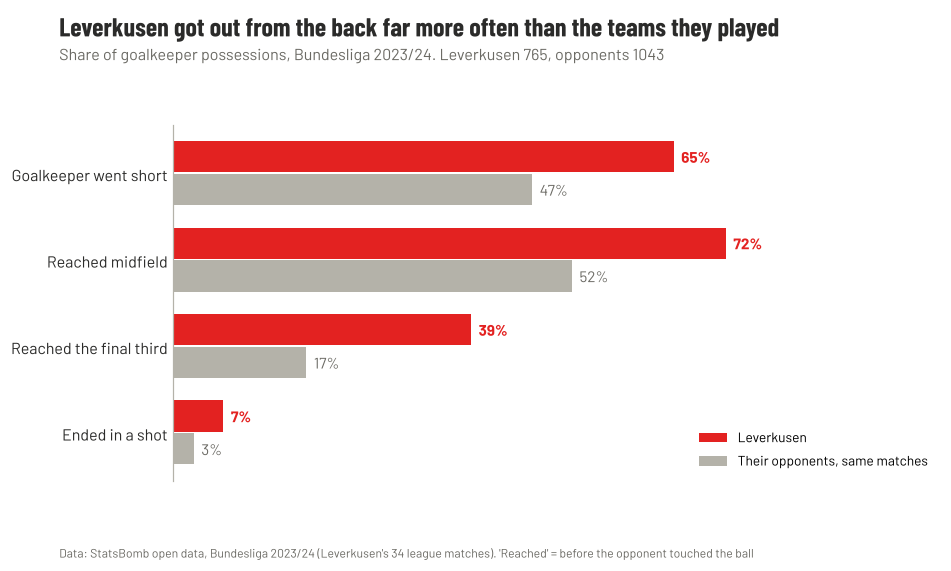

In [8]:
# Figure 1: Leverkusen vs opponents
labels = ["Goalkeeper went short", "Reached midfield", "Reached the final third", "Ended in a shot"]
cols = ["short", "reached_midfield", "reached_final_third", "ended_in_shot"]
lev = [SUM.loc[c, "Leverkusen"] for c in cols]
opp = [SUM.loc[c, "Opponents"] for c in cols]
fig, ax = plt.subplots(figsize=(9, 4.2))
yy = np.arange(len(labels))[::-1]
ax.barh(yy + 0.19, lev, height=0.36, color=RED, label="Leverkusen")
ax.barh(yy - 0.19, opp, height=0.36, color=GREY, label="Their opponents, same matches")
for y0, a, b in zip(yy, lev, opp):
    ax.text(a + 0.01, y0 + 0.19, f"{a:.0%}", va="center", fontsize=10, color=RED, fontweight="bold")
    ax.text(b + 0.01, y0 - 0.19, f"{b:.0%}", va="center", fontsize=10, color=MUTED)
ax.set_yticks(yy, labels, fontsize=10.5)
ax.set_xlim(0, 1); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False, fontsize=9)
titles(fig, "Leverkusen got out from the back far more often than the teams they played",
       f"Share of goalkeeper possessions, Bundesliga 2023/24. Leverkusen {int(SUM.loc['possessions','Leverkusen'])}, opponents {int(SUM.loc['possessions','Opponents'])}",
       SRC + ". 'Reached' = before the opponent touched the ball")
fig.savefig(FIGS / "01_leverkusen_vs_opponents.png")

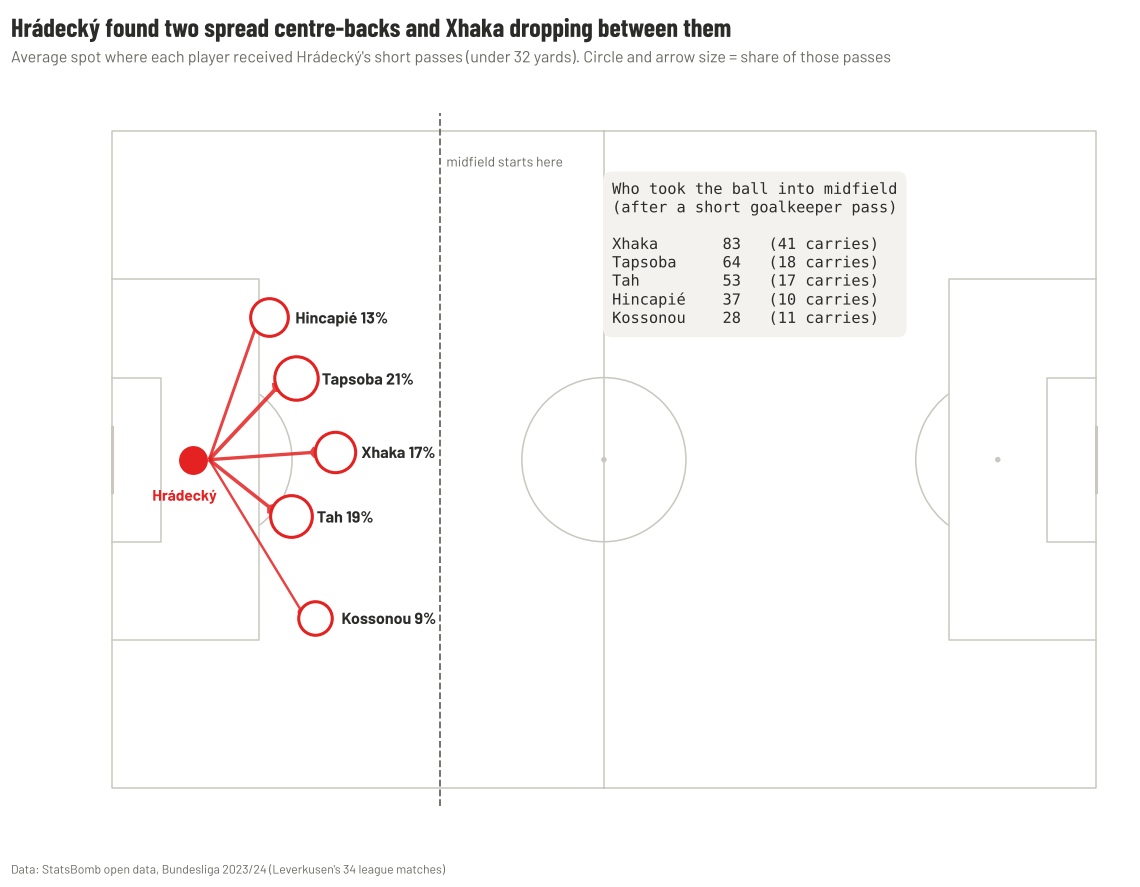

In [9]:
# Figure 2: where the keeper's short passes went, and who took the ball into midfield
pitch = Pitch(pitch_type="statsbomb", pitch_color="white", line_color="#C9C7BF", linewidth=1)
fig, ax = pitch.draw(figsize=(11, 7.3))
top = REC.head(5)
SHORT = {"Edmond Fayçal Tapsoba": "Tapsoba", "Jonathan Tah": "Tah", "Granit Xhaka": "Xhaka",
         "Piero Martín Hincapié Reyna": "Hincapié", "Odilon Kossonou": "Kossonou", "Josip Stanišić": "Stanišić",
         "Alejandro Grimaldo García": "Grimaldo", "Exequiel Alejandro Palacios": "Palacios", "Lukáš Hrádecký": "Hrádecký",
         "Robert Andrich": "Andrich", "Jeremie Frimpong": "Frimpong", "Florian Wirtz": "Wirtz"}
gx, gy = S.rec_x.notna(), None
gkx = E[(E.type == "Pass") & (E.player == "Lukáš Hrádecký")].x.median()
gky = 40
for name, r in top.iterrows():
    pitch.arrows(gkx + 2, gky, r.x - 1.2, r.y, ax=ax, width=1 + 7 * r.share, headwidth=3.5, headlength=3.5,
                 color=RED, alpha=0.85, zorder=2)
    pitch.scatter(r.x, r.y, s=260 + 2600 * r.share, ax=ax, color="white", edgecolors=RED, linewidth=2, zorder=3)
    pitch.annotate(f"{SHORT.get(name, name)} {r.share:.0%}", (r.x + 3.2, r.y),
                   ax=ax, ha="left", va="center", fontsize=10.5, color=DARK, fontweight="bold", zorder=4)
pitch.scatter(gkx, gky, s=320, ax=ax, color=RED, zorder=3)
pitch.annotate("Hrádecký", (gkx - 1, gky + 5), ax=ax, ha="center", fontsize=10, color=RED, fontweight="bold")
ax.axvline(40, color=MUTED, lw=1.2, ls="--", ymin=0.02, ymax=0.98)
ax.text(40.8, 2.6, "midfield starts here", fontsize=9, color=MUTED, va="top")
it = INTO.drop(index="Lukáš Hrádecký", errors="ignore").head(5)
txt = "Who took the ball into midfield\n(after a short goalkeeper pass)\n\n" + "\n".join(
    f"{SHORT.get(n, n):<10} {r.total:>3}   ({r.get('Carry', 0)} carries)" for n, r in it.iterrows())
ax.text(61, 6, txt, fontsize=10, color=DARK, va="top", family="monospace",
        bbox=dict(boxstyle="round,pad=0.6", fc=LIGHT, ec="none"))
titles(fig, "Hrádecký found two spread centre-backs and Xhaka dropping between them",
       "Average spot where each player received Hrádecký's short passes (under 32 yards). Circle and arrow size = share of those passes",
       SRC, y=0.99)
fig.savefig(FIGS / "02_where_the_keeper_passes_go.png")

        minute  second              team                       player   type      x     y     ex    ey pass_outcome
105573      52      17  Bayer Leverkusen               Lukáš Hrádecký   Pass    4.8  41.0    8.4  27.5          NaN
105575      52      18  Bayer Leverkusen  Piero Martín Hincapié Reyna  Carry    8.4  27.5   19.7  26.5          NaN
105576      52      22  Bayer Leverkusen  Piero Martín Hincapié Reyna   Pass   19.7  26.5   35.8  28.8          NaN
105579      52      24  Bayer Leverkusen                Florian Wirtz  Carry   35.8  28.8   38.6  27.1          NaN
105580      52      24  Bayer Leverkusen                Florian Wirtz   Pass   38.6  27.1   28.9  20.7          NaN
105582      52      25  Bayer Leverkusen                 Granit Xhaka  Carry   28.9  20.7   28.7  20.7          NaN
105583      52      26  Bayer Leverkusen                 Granit Xhaka   Pass   28.7  20.7   50.3  52.6          NaN
105585      52      28  Bayer Leverkusen                  Adam Hložek  C

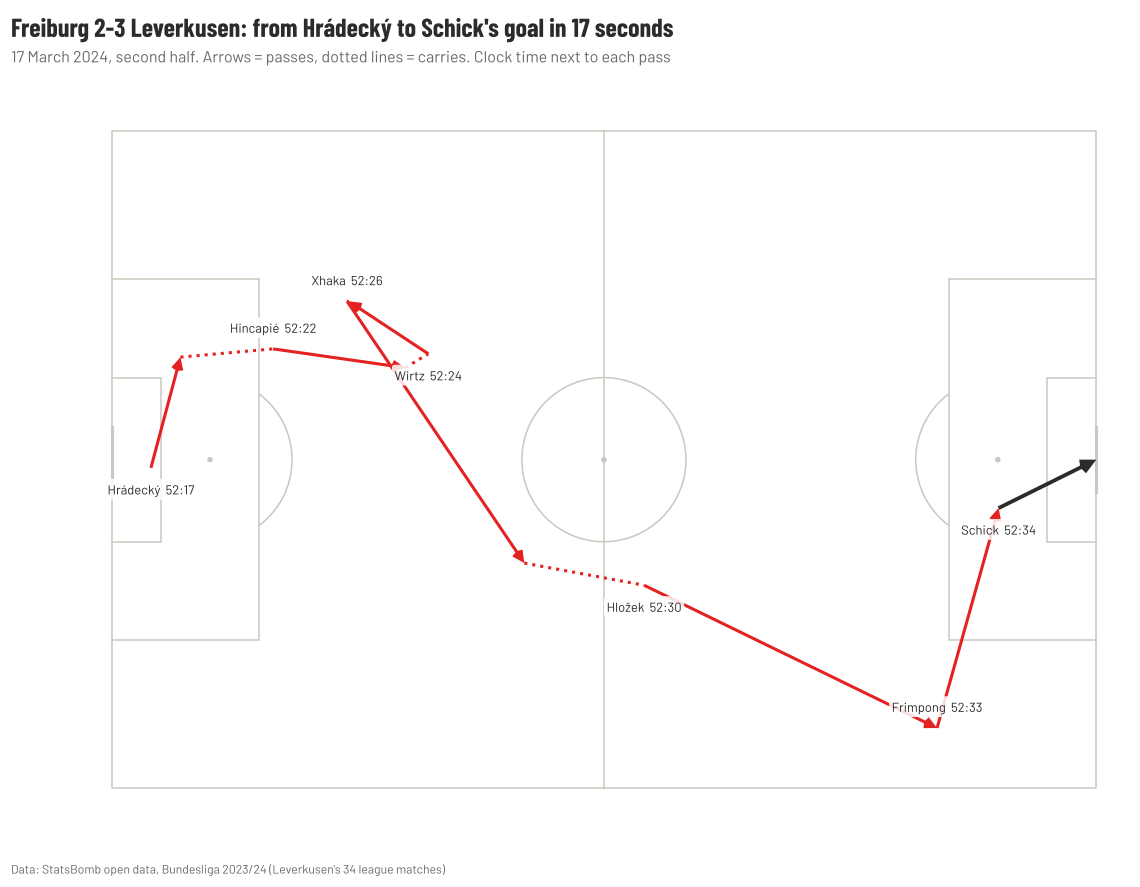

In [10]:
# Figure 3: Schick's goal at Freiburg, 17 March 2024 (into midfield through Xhaka)
pick = [i for i, r in L.iterrows() if r.goal and "Freiburg 2-3" in r.match and r.clock == "52:17"]
i = pick[0]
mid_, clock = L.loc[i, "match_id"], L.loc[i, "clock"]
t0 = int(clock.split(":")[0]) * 60 + int(clock.split(":")[1])
seq = E[(E.match_id == mid_) & (E.minute * 60 + E.second >= t0)]
gl = seq[(seq.team == LEV) & (seq.type == "Shot") & (seq.shot_outcome == "Goal")].iloc[0]
seq = seq[seq["index"] <= gl["index"]]
seq = seq[seq.type.isin(["Pass", "Carry", "Shot"])]
print(seq[["minute", "second", "team", "player", "type", "x", "y", "ex", "ey", "pass_outcome"]].to_string())
fig, ax = pitch.draw(figsize=(11, 7.3))
step = 0
for _, r in seq.iterrows():
    lev_ = r.team == LEV
    c = RED if lev_ else GREY
    if r.type == "Pass":
        pitch.arrows(r.x, r.y, r.ex, r.ey, ax=ax, width=2, headwidth=4, headlength=4, color=c, zorder=3,
                     alpha=1 if pd.isna(r.pass_outcome) else 0.45)
    elif r.type == "Carry":
        pitch.lines(r.x, r.y, r.ex, r.ey, ax=ax, lw=2, ls=":", color=c, zorder=2)
    else:
        pitch.arrows(r.x, r.y, 120, 40, ax=ax, width=2.5, headwidth=4, headlength=4, color=DARK, zorder=3)
    if lev_ and r.type in ("Pass", "Shot"):
        step += 1
        pitch.annotate(f"{SHORT.get(r.player, r.player.split()[-1])}  {r.minute}:{r.second:02d}", (r.x, r.y + (2.6 if step % 2 else -2.6)),
                       ax=ax, fontsize=8.5, color=DARK, ha="center", va="center", zorder=4,
                       bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
secs = (gl.minute * 60 + gl.second) - t0
titles(fig, f"Freiburg 2-3 Leverkusen: from Hrádecký to Schick's goal in {secs} seconds",
       "17 March 2024, second half. Arrows = passes, dotted lines = carries. Clock time next to each pass",
       SRC, y=0.99)
fig.savefig(FIGS / "03_freiburg_goal_sequence.png")

## 5. The one-page report

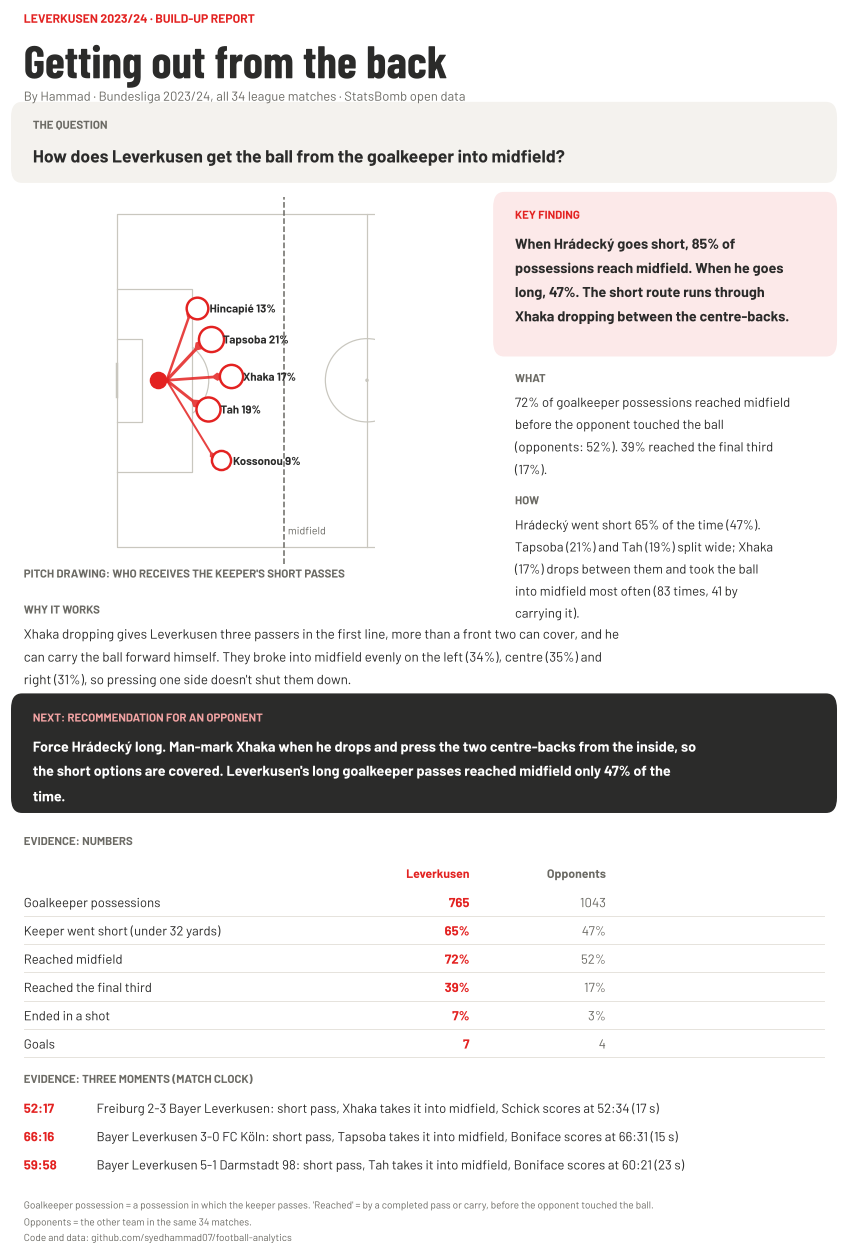

In [11]:
import textwrap
from matplotlib.patches import FancyBboxPatch
pct = lambda v: f"{v:.0%}"
lev, opp = SUM["Leverkusen"], SUM["Opponents"]
sh_mid = BY_LEN.loc[("Leverkusen", True), "midfield"]; lg_mid = BY_LEN.loc[("Leverkusen", False), "midfield"]
r_tap, r_tah, r_xha = (REC.loc[n, "share"] for n in ["Edmond Fayçal Tapsoba", "Jonathan Tah", "Granit Xhaka"])
x_into = INTO.loc["Granit Xhaka"]
lanes = pd.cut(B.into_mid_y, [0, 26.7, 53.3, 80], labels=["left", "centre", "right"], include_lowest=True).value_counts(normalize=True)
moments = []
for want, route in [("Freiburg 2-3", "Xhaka"), ("3-0 FC Köln", "Tapsoba"), ("5-1 Darmstadt", "Tah")]:
    r = GOALS[GOALS.match.str.contains(want)].iloc[0]
    moments.append((r.clock, f"{r.match}: short pass, {route} takes it into midfield, {r.scorer.split()[-1] if 'Boniface' not in r.scorer else 'Boniface'} scores at {r.goal_clock} ({int(r.seconds)} s)"))

W, H = 8.27, 11.69
fig = plt.figure(figsize=(W, H)); fig.patch.set_facecolor("white")
def box(x, y, w, h, fc=LIGHT):
    fig.add_artist(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.004,rounding_size=0.012", fc=fc, ec="none", transform=fig.transFigure, zorder=0))
def label(x, y, t, c=MUTED): fig.text(x, y, t.upper(), fontsize=7.5, color=c, fontweight="bold", va="top")
def body(x, y, t, width=60, size=9.2, c=DARK, weight="normal"):
    fig.text(x, y, "\n".join(textwrap.wrap(t, width)), fontsize=size, color=c, va="top", linespacing=1.4, fontweight=weight)

fig.text(0.06, 0.965, "LEVERKUSEN 2023/24 · BUILD-UP REPORT", fontsize=8, color=RED, fontweight="bold", va="top")
fig.text(0.06, 0.948, "Getting out from the back", fontsize=30, color=DARK, fontweight="bold", va="top", family="Barlow Condensed")
fig.text(0.06, 0.905, "By Hammad · Bundesliga 2023/24, all 34 league matches · StatsBomb open data", fontsize=8.5, color=MUTED, va="top")

box(0.05, 0.835, 0.90, 0.055); label(0.07, 0.882, "The question")
body(0.07, 0.862, "How does Leverkusen get the ball from the goalkeeper into midfield?", width=90, size=11.5, weight="bold")

# pitch drawing
axp = fig.add_axes([0.05, 0.535, 0.50, 0.285])
pt = Pitch(pitch_type="statsbomb", pitch_color="white", line_color="#C9C7BF", linewidth=0.8, half=False)
pt.draw(ax=axp); axp.set_xlim(-2, 62)
for name, r in REC.head(5).iterrows():
    pt.arrows(gkx + 2, gky, r.x - 1.2, r.y, ax=axp, width=0.8 + 6 * r.share, headwidth=3, headlength=3, color=RED, alpha=0.85, zorder=2)
    pt.scatter(r.x, r.y, s=80 + 900 * r.share, ax=axp, color="white", edgecolors=RED, linewidth=1.6, zorder=3)
    pt.annotate(f"{SHORT.get(name, name)} {r.share:.0%}", (r.x + 3, r.y), ax=axp, ha="left", va="center", fontsize=7.5, color=DARK, fontweight="bold")
pt.scatter(gkx, gky, s=110, ax=axp, color=RED, zorder=3)
axp.axvline(40, color=MUTED, lw=1, ls="--")
axp.text(41, 77, "midfield", fontsize=7, color=MUTED)
label(0.06, 0.533, "Pitch drawing: who receives the keeper's short passes")

# key finding + what/how/why
box(0.58, 0.700, 0.37, 0.120, fc="#FCE9E9"); label(0.60, 0.812, "Key finding", RED)
body(0.60, 0.792, f"When Hrádecký goes short, {pct(sh_mid)} of possessions reach midfield. When he goes long, {pct(lg_mid)}. The short route runs through Xhaka dropping between the centre-backs.", width=40, size=9.4, weight="bold")
label(0.60, 0.685, "What"); body(0.60, 0.668, f"{pct(lev.reached_midfield)} of goalkeeper possessions reached midfield before the opponent touched the ball (opponents: {pct(opp.reached_midfield)}). {pct(lev.reached_final_third)} reached the final third ({pct(opp.reached_final_third)}).", width=46, size=8.6)
label(0.60, 0.590, "How"); body(0.60, 0.573, f"Hrádecký went short {pct(lev.short)} of the time ({pct(opp.short)}). Tapsoba ({pct(r_tap)}) and Tah ({pct(r_tah)}) split wide; Xhaka ({pct(r_xha)}) drops between them and took the ball into midfield most often ({int(x_into.total)} times, {int(x_into.Carry)} by carrying it).", width=46, size=8.6)
label(0.06, 0.505, "Why it works")
body(0.06, 0.488, f"Xhaka dropping gives Leverkusen three passers in the first line, more than a front two can cover, and he can carry the ball forward himself. They broke into midfield evenly on the left ({pct(lanes['left'])}), centre ({pct(lanes['centre'])}) and right ({pct(lanes['right'])}), so pressing one side doesn't shut them down.", width=105, size=8.8)

box(0.05, 0.345, 0.90, 0.085, fc=DARK); fig.text(0.07, 0.421, "NEXT: RECOMMENDATION FOR AN OPPONENT", fontsize=7.5, color="#F2A3A3", fontweight="bold", va="top")
body(0.07, 0.401, f"Force Hrádecký long. Man-mark Xhaka when he drops and press the two centre-backs from the inside, so the short options are covered. Leverkusen's long goalkeeper passes reached midfield only {pct(lg_mid)} of the time.", width=100, size=9.4, c="white", weight="bold")

label(0.06, 0.325, "Evidence: numbers")
rows_ = [("Goalkeeper possessions", f"{int(lev.possessions)}", f"{int(opp.possessions)}"),
         ("Keeper went short (under 32 yards)", pct(lev.short), pct(opp.short)),
         ("Reached midfield", pct(lev.reached_midfield), pct(opp.reached_midfield)),
         ("Reached the final third", pct(lev.reached_final_third), pct(opp.reached_final_third)),
         ("Ended in a shot", pct(lev.ended_in_shot), pct(opp.ended_in_shot)),
         ("Goals", f"{int(lev.goals)}", f"{int(opp.goals)}")]
y0 = 0.300
fig.text(0.55, y0, "Leverkusen", fontsize=8, color=RED, fontweight="bold", va="top", ha="right")
fig.text(0.70, y0, "Opponents", fontsize=8, color=MUTED, fontweight="bold", va="top", ha="right")
for k, (a, b, c) in enumerate(rows_):
    yy_ = y0 - 0.022 * (k + 1)
    fig.text(0.06, yy_, a, fontsize=8.6, color=DARK, va="top"); fig.text(0.55, yy_, b, fontsize=8.6, color=RED, va="top", ha="right", fontweight="bold")
    fig.text(0.70, yy_, c, fontsize=8.6, color=MUTED, va="top", ha="right")
    fig.add_artist(plt.Line2D([0.06, 0.94], [yy_ - 0.017, yy_ - 0.017], color="#E4E1DA", lw=0.6, transform=fig.transFigure))
label(0.06, 0.140, "Evidence: three moments (match clock)")
for k, (clk, txt) in enumerate(moments):
    yy_ = 0.118 - 0.022 * k
    fig.text(0.06, yy_, clk, fontsize=8.6, color=RED, fontweight="bold", va="top")
    fig.text(0.14, yy_, txt, fontsize=8.6, color=DARK, va="top")
fig.text(0.06, 0.042, "Goalkeeper possession = a possession in which the keeper passes. 'Reached' = by a completed pass or carry, before the opponent touched the ball.\n"
         "Opponents = the other team in the same 34 matches.", fontsize=6.6, color=MUTED, va="top", linespacing=1.4)
fig.text(0.06, 0.016, "Code and data: github.com/syedhammad07/football-analytics", fontsize=6.6, color=MUTED, va="top")
fig.savefig(ROOT / "reports" / "Leverkusen_build_up_one_page.pdf", bbox_inches=None)
fig.savefig(ROOT / "reports" / "Leverkusen_build_up_one_page.png", bbox_inches=None, dpi=200)